# 1. First look at the data

Before running any statistics, a good analyst just *looks* at the data. This
notebook does that: who the users are, where they drop off in the sign-up
journey, and whether our experiment split people fairly.

**Plain-English note.** The data here is *synthetic* — made up by a simulator in
this repo so we can test the method against a known answer. No real customer data
is used. But it is designed to behave like the real KiwiSaver sign-up flow.

## How to read this notebook

- Cells with code produce the numbers and pictures.
- The text between them explains, in everyday language, **what we're seeing and
  why it matters**. No prior stats knowledge needed.

In [1]:
import sys, duckdb
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, "../src")
import analyze as az

DB = "../warehouse.duckdb"
users = az.q(DB, "select * from mart_experiment_users")
funnel = az.q(DB, "select * from mart_funnel_steps")
primary = az.q(DB, "select * from mart_primary_metric").set_index("variant")
users.shape, funnel.shape

((40000, 22), (14, 6))

## 2. The sign-up journey (the "funnel")

Think of the sign-up journey as a funnel: lots of people enter at the top, and
each step loses some. The next chart shows how many people made it to each step,
for each of the two versions of the app (A = the original fund list, B = the new
quiz).

variant,step_order,step_name,A,B
0,0,viewed kiwisaver landing,1.000,1.000
1,1,started questionnaire,0.623,0.619
2,2,completed questionnaire,0.527,0.525
3,3,viewed fund selection,0.502,0.498
4,4,selected base fund,0.276,0.309
5,5,confirmed plan,0.222,0.237
6,6,submitted application,0.199,0.212


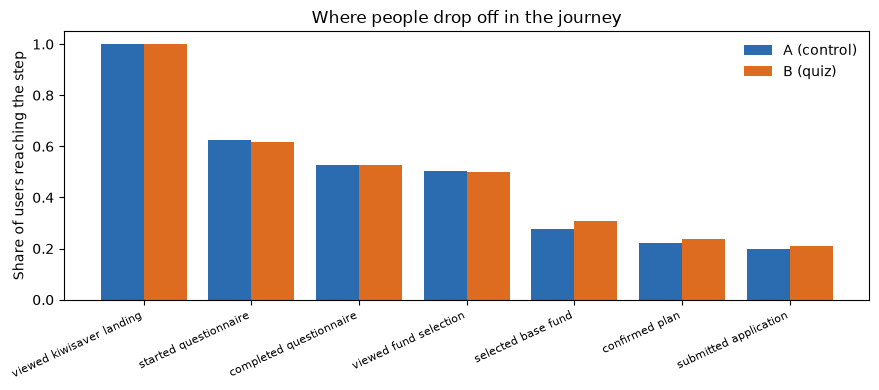

In [2]:
pivot = (funnel.pivot_table(index=["step_order","step_name"], columns="variant",
                            values="pct_of_assigned").sort_values("step_order").reset_index())
pivot["step_name"] = pivot["step_name"].str.replace("_", " ")
display(pivot.round(3))

x = list(range(len(pivot)))
plt.figure(figsize=(9,4))
plt.bar([i-0.2 for i in x], pivot["A"], 0.4, label='A (control)', color=az.BLUE)
plt.bar([i+0.2 for i in x], pivot["B"], 0.4, label='B (quiz)', color=az.ORANGE)
plt.xticks(x, pivot["step_name"], rotation=25, ha='right', fontsize=8)
plt.ylabel("Share of users reaching the step")
plt.title("Where people drop off in the journey")
plt.legend(frameon=False)
plt.tight_layout(); plt.show()

**What this tells us.** The biggest drop is *before* anyone even reaches the
fund-selection step — most people who open the KiwiSaver page don't start the
questionnaire. That's important: our experiment only changes the *fund-picking*
step, so we deliberately measure success from the point people reach that step
(the fair "starting line" for both versions). Otherwise the earlier drop-off —
which is identical in both groups — would just add noise.

## 3. Who are our users?

A quick look at the kinds of people in the experiment, so we know the result
isn't skewed to one group.

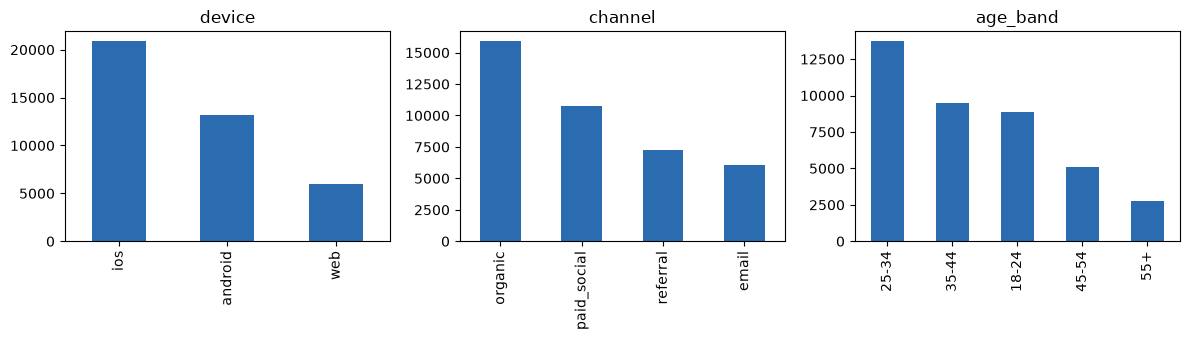

,users
is_existing_kiwisaver,
False,11932
True,28068


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12,3.5))
for ax, col in zip(axes, ["device", "channel", "age_band"]):
    users[col].value_counts().plot(kind="bar", ax=ax, color=az.BLUE)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()

display(users.groupby("is_existing_kiwisaver").size().rename("users").to_frame())

## 4. Did our random split work?

We flipped a coin to decide who saw A and who saw B. If that worked, the two
groups should be a similar mix of people — the same *only* difference being the
screen they saw. This is called a **balance check**, and the related tripwire is
called **SRM** (sample-ratio mismatch).

In [4]:
split = users.variant.value_counts(normalize=True).round(3)
print("Share of users by arm:"); print(split)

for col in ["device", "channel", "is_existing_kiwisaver", "age_band"]:
    share = users.groupby(["variant", col]).size().unstack(0)
    share = (share / share.sum()).round(2)
    print(f"\n{col}:"); display(share)

Share of users by arm:
variant
B    0.503
A    0.497
Name: proportion, dtype: float64

device:


variant,A,B
device,,
android,0.33,0.33
ios,0.52,0.52
web,0.15,0.15



channel:


variant,A,B
channel,,
email,0.15,0.15
organic,0.40,0.40
paid_social,0.27,0.27
referral,0.18,0.18



is_existing_kiwisaver:


variant,A,B
is_existing_kiwisaver,,
False,0.3,0.3
True,0.7,0.7



age_band:


variant,A,B
age_band,,
18-24,0.22,0.22
25-34,0.34,0.34
35-44,0.24,0.24
45-54,0.13,0.13
55+,0.07,0.07


**What this tells us.** The split is very close to 50/50, and each group has a
similar mix of devices, channels and ages. That's exactly what we want: it means
any difference in results later can be credited to *the change*, not to one group
happening to have keener people in it.

## 5. A first peek at the result

Here's the headline our experiment is trying to move, before any statistics: the
share of people who **finish signing up within 7 days** of reaching the fund
screen.

In [5]:
display((primary[["reached_selection_users","converted_users","conversion_rate"]]
         .assign(conversion_rate=lambda d: (d.conversion_rate*100).round(2))))
print(f"B minus A = {(primary.loc['B','conversion_rate']-primary.loc['A','conversion_rate'])*100:.2f} percentage points")

,reached_selection_users,converted_users,conversion_rate
variant,,,
A,9980,3946.0,39.54
B,10023,4265.0,42.55


B minus A = 3.01 percentage points


**What this tells us.** Version B looks a bit better. But "looks better" isn't
enough — with thousands of people, small gaps can appear by chance. The next
notebook asks the real question: **how sure are we, and what should we do about
it?** → continue to `02_ab_test.ipynb`.